# 05. Unsupervised Market Regime Clustering (K-Means & DBSCAN)
### Integrated Project: AI-Based Intelligent Trading System — Assignment 5 (Multi-Company Upgrade)

---

## 1. Title and Objective

### Understanding Market Regimes in Quantitative Trading
Financial markets are non-stationary dynamic systems that transition between distinct behavioral states known as **market regimes** (e.g., calm trending periods, high-volatility expansions, liquidity crunches, and severe drawdowns). A predictive model or trading policy trained exclusively on bull-market conditions will often fail during market corrections.

### The Scale-Normalization Imperative for Multi-Asset Universes
When clustering across a single stock (e.g., AAPL), raw price ranges ($) and share volumes are relatively homogeneous. However, across a **10-company multi-asset equity universe** (`AAPL`, `MSFT`, `GOOGL`, `AMZN`, `NVDA`, `META`, `TSLA`, `JPM`, `V`, `JNJ`), nominal share prices vary from ~$30 to ~$500+, and average daily trading volumes differ by over an order of magnitude (tens of millions vs. hundreds of millions of shares). 

Clustering on raw dollar amounts or unnormalized share counts causes the algorithm to group stocks primarily by nominal price levels or capital structure rather than intrinsic market behavior.

To solve this, we engineer **7 company-scale-normalized behavioral features**:
1. **`Daily_Return`**: Percentage return from prior close ($R_t = (C_t - C_{t-1})/C_{t-1}$).
2. **`Normalized_Price_Range`**: Daily trading range relative to closing price ($\\frac{High - Low}{Close}$).
3. **`Normalized_Candle_Body`**: Directional candlestick body relative to closing price ($\\frac{Close - Open}{Close}$).
4. **`Normalized_Upper_Shadow`**: Upper wick relative to closing price ($\\frac{High - \\max(Open, Close)}{Close}$).
5. **`Normalized_Lower_Shadow`**: Lower wick relative to closing price ($\\frac{\\min(Open, Close) - Low}{Close}$).
6. **`Volatility_5`**: 5-day rolling standard deviation of daily returns.
7. **`Relative_Volume`**: Trading volume normalized by its 20-day historical moving average ($\\frac{Volume_t}{\\text{SMA}_{20}(Volume)}$), computed strictly per ticker.

### Strict Anti-Leakage Guarantee
- **No Forward-Looking Targets**: Unsupervised clustering uses zero target labels (`Target_Next_Close`, `Target_Next_Day`), zero future dates, and zero predictions from prior models.
- **Strictly Backward-Looking Rolling Windows**: `Relative_Volume` uses past volume up to session $t$ ($t, t-1, \dots, t-19$) within each company. Zero future bars are consulted.

### Multi-Company Asset Scope
- 10 companies across tech, retail, finance, and healthcare: `AAPL`, `MSFT`, `GOOGL`, `AMZN`, `NVDA`, `META`, `TSLA`, `JPM`, `V`, `JNJ`.
- 15,010 total observations (1,501 rows per ticker from 2019-01-15 through 2024-12-31).
- Every observation receives a regime cluster label for downstream use in **Assignment 6 (RL Agent)** and **Assignment 8 (Decision Fusion)**.


---

## 2. Import Libraries
We import scientific packages, clustering algorithms (`KMeans`, `DBSCAN`), `PCA` for 2D visualization, `StandardScaler`, and validation metrics (`silhouette_score`).


In [1]:
import os
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

# Ensure project root is in the Python path
PROJECT_ROOT = Path("..").resolve() if Path("..").resolve().name == "AI-Intelligent-Trading-System" else Path(".").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# Configure visualization aesthetics
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 10

print(f"Project Root: {PROJECT_ROOT}")
print("Clustering libraries imported successfully!")


Project Root: C:\Users\pushk\OneDrive\Desktop\Pushkar\AI-Intelligent-Trading-System
Clustering libraries imported successfully!


---

## 3. Dataset Loading & Feature Engineering: 7 Scale-Normalized Features
We load `data/processed/multi_company_features.csv` (15,010 rows) and construct the 7 scale-normalized behavioral features.

### Anti-Leakage Verification:
1. `Normalized_Price_Range`, `Normalized_Candle_Body`, `Normalized_Upper_Shadow`, and `Normalized_Lower_Shadow` are calculated strictly from contemporaneous OHLC values on day $t$.
2. `Relative_Volume` uses `df.groupby('Ticker')['Volume'].transform(lambda s: s / s.rolling(20, min_periods=1).mean())`. 
   - Rolling mean uses a backward-looking window $[t-19, t]$.
   - Computation is grouped by `Ticker`, guaranteeing no cross-company leakage.
   - `min_periods=1` prevents dropping initial warmup rows, preserving all 15,010 observations.


In [2]:
features_path = PROJECT_ROOT / "data" / "processed" / "multi_company_features.csv"
df_features = pd.read_csv(features_path)
df_features["Date"] = pd.to_datetime(df_features["Date"])
df_features = df_features.sort_values(by=["Ticker", "Date"]).reset_index(drop=True)

EXPECTED_TICKERS = sorted(["AAPL", "MSFT", "GOOGL", "AMZN", "NVDA", "META", "TSLA", "JPM", "V", "JNJ"])
COMPANY_NAMES = {
    "AAPL": "Apple", "MSFT": "Microsoft", "GOOGL": "Alphabet", "AMZN": "Amazon",
    "NVDA": "NVIDIA", "META": "Meta Platforms", "TSLA": "Tesla", "JPM": "JPMorgan Chase",
    "V": "Visa", "JNJ": "Johnson & Johnson"
}

# Construct the 4 scale-normalized candlestick/price features
df_features["Normalized_Price_Range"] = df_features["Price_Range"] / df_features["Close"]
df_features["Normalized_Candle_Body"] = df_features["Candle_Body"] / df_features["Close"]
df_features["Normalized_Upper_Shadow"] = df_features["Upper_Shadow"] / df_features["Close"]
df_features["Normalized_Lower_Shadow"] = df_features["Lower_Shadow"] / df_features["Close"]

# Construct Relative Volume (rolling 20-day volume mean strictly per ticker)
df_features["Relative_Volume"] = df_features.groupby("Ticker")["Volume"].transform(
    lambda s: s / s.rolling(20, min_periods=1).mean()
)

clustering_features = [
    "Daily_Return",
    "Normalized_Price_Range",
    "Normalized_Candle_Body",
    "Normalized_Upper_Shadow",
    "Normalized_Lower_Shadow",
    "Volatility_5",
    "Relative_Volume"
]

print(f"Loaded Dataset Shape: {df_features.shape[0]:,} rows, {df_features.shape[1]} columns")
print(f"7 Scale-Normalized Clustering Features: {clustering_features}")

# Strict integrity checks
null_counts = df_features[clustering_features].isnull().sum()
assert null_counts.sum() == 0, f"Missing values detected: {null_counts.to_dict()}"
dup_count = df_features.duplicated(subset=["Ticker", "Date"]).sum()
assert dup_count == 0, f"Found {dup_count} duplicate rows!"
assert len(df_features) == 15010, f"Expected 15,010 rows, got {len(df_features)}"

# Verify Anti-Leakage properties of Relative_Volume
first_ticker_df = df_features[df_features["Ticker"] == "AAPL"].copy()
manual_rolling = first_ticker_df["Volume"].iloc[:5].mean()
calc_rolling = first_ticker_df["Volume"].iloc[4] / first_ticker_df["Relative_Volume"].iloc[4]
assert np.isclose(manual_rolling, calc_rolling), "Rolling volume window calculation discrepancy!"

print("Integrity verification: Zero missing values, zero duplicates across all 15,010 rows.")
print("Anti-leakage verified: Relative_Volume is strictly backward-looking per ticker.")

# Display summary statistics of the normalized features
display(df_features[clustering_features].describe().T[["count", "mean", "std", "min", "50%", "max"]])


Loaded Dataset Shape: 15,010 rows, 20 columns
7 Scale-Normalized Clustering Features: ['Daily_Return', 'Normalized_Price_Range', 'Normalized_Candle_Body', 'Normalized_Upper_Shadow', 'Normalized_Lower_Shadow', 'Volatility_5', 'Relative_Volume']
Integrity verification: Zero missing values, zero duplicates across all 15,010 rows.
Anti-leakage verified: Relative_Volume is strictly backward-looking per ticker.


,count,mean,std,min,50%,max
Daily_Return,15010.0,0.001308,0.024065,-0.263901,0.001187,0.243696
Normalized_Price_Range,15010.0,0.025351,0.017011,0.003749,0.020625,0.218735
Normalized_Candle_Body,15010.0,0.000275,0.018108,-0.146654,0.000651,0.136295
Normalized_Upper_Shadow,15010.0,0.006174,0.006792,0.000000,0.004247,0.092361
Normalized_Lower_Shadow,15010.0,0.006564,0.006839,0.000000,0.004695,0.097767
Volatility_5,15010.0,0.019238,0.014827,0.001164,0.015026,0.147880
Relative_Volume,15010.0,1.004689,0.379868,0.143070,0.924412,5.871968


---

## 4. Feature Standardization (StandardScaler)
Because Euclidean distance in K-Means and density radius in DBSCAN are sensitive to the absolute dispersion of each variable, we standardize all 7 behavioral features to zero mean ($\\mu = 0$) and unit variance ($\\sigma = 1$):

$$z = \\frac{x - \\mu}{\\sigma}$$

This ensures that `Daily_Return` (typically ~0.02 std) and `Relative_Volume` (typically ~0.38 std) contribute equitably to distance calculations without artificial scale distortion.


In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_features[clustering_features].values)

print("=== Feature Scaling Verification ===")
df_scaled_check = pd.DataFrame(X_scaled, columns=clustering_features)
print("Scaled Means (expected ~0.0):")
print(df_scaled_check.mean().round(6).to_dict())
print("\nScaled Standard Deviations (expected 1.0):")
print(df_scaled_check.std().round(6).to_dict())


=== Feature Scaling Verification ===
Scaled Means (expected ~0.0):
{'Daily_Return': -0.0, 'Normalized_Price_Range': -0.0, 'Normalized_Candle_Body': 0.0, 'Normalized_Upper_Shadow': -0.0, 'Normalized_Lower_Shadow': 0.0, 'Volatility_5': -0.0, 'Relative_Volume': -0.0}

Scaled Standard Deviations (expected 1.0):
{'Daily_Return': 1.000033, 'Normalized_Price_Range': 1.000033, 'Normalized_Candle_Body': 1.000033, 'Normalized_Upper_Shadow': 1.000033, 'Normalized_Lower_Shadow': 1.000033, 'Volatility_5': 1.000033, 'Relative_Volume': 1.000033}


---

## 5. K-Means Evaluation ($K=2$ to $K=8$)
We evaluate cluster counts from $K=2$ through $K=8$ using two complementary quantitative criteria:
1. **Inertia (Within-Cluster Sum of Squares - WCSS)**: Measures cluster compactness. Inertia decreases monotonically as $K$ increases; we look for the "elbow point" where the rate of decrease drops sharply.
2. **Silhouette Score**: Measures how well-separated clusters are relative to inter-cluster distances, bounded in $[-1, +1]$. A higher silhouette indicates tighter, more distinct clusters.


In [4]:
k_values = list(range(2, 9))
inertias = []
silhouette_scores = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertia = km.inertia_
    sil = silhouette_score(X_scaled, labels)
    inertias.append(inertia)
    silhouette_scores.append(sil)
    print(f"K = {k}: Inertia = {inertia:10.2f} | Silhouette Score = {sil:.4f}")

df_kmeans_eval = pd.DataFrame({
    "K": k_values,
    "Inertia": [round(i, 2) for i in inertias],
    "Silhouette_Score": [round(s, 4) for s in silhouette_scores]
})

print("\n=== K-Means Quantitative Evaluation Table ===")
display(df_kmeans_eval)


K = 2: Inertia =   82442.52 | Silhouette Score = 0.4362


K = 3: Inertia =   69782.45 | Silhouette Score = 0.4009


K = 4: Inertia =   63409.64 | Silhouette Score = 0.3086


K = 5: Inertia =   58942.07 | Silhouette Score = 0.2797


K = 6: Inertia =   54803.07 | Silhouette Score = 0.2272


K = 7: Inertia =   50999.96 | Silhouette Score = 0.2232


K = 8: Inertia =   47834.59 | Silhouette Score = 0.2234

=== K-Means Quantitative Evaluation Table ===


,K,Inertia,Silhouette_Score
0,2,82442.52,0.4362
1,3,69782.45,0.4009
2,4,63409.64,0.3086
3,5,58942.07,0.2797
4,6,54803.07,0.2272
5,7,50999.96,0.2232
6,8,47834.59,0.2234


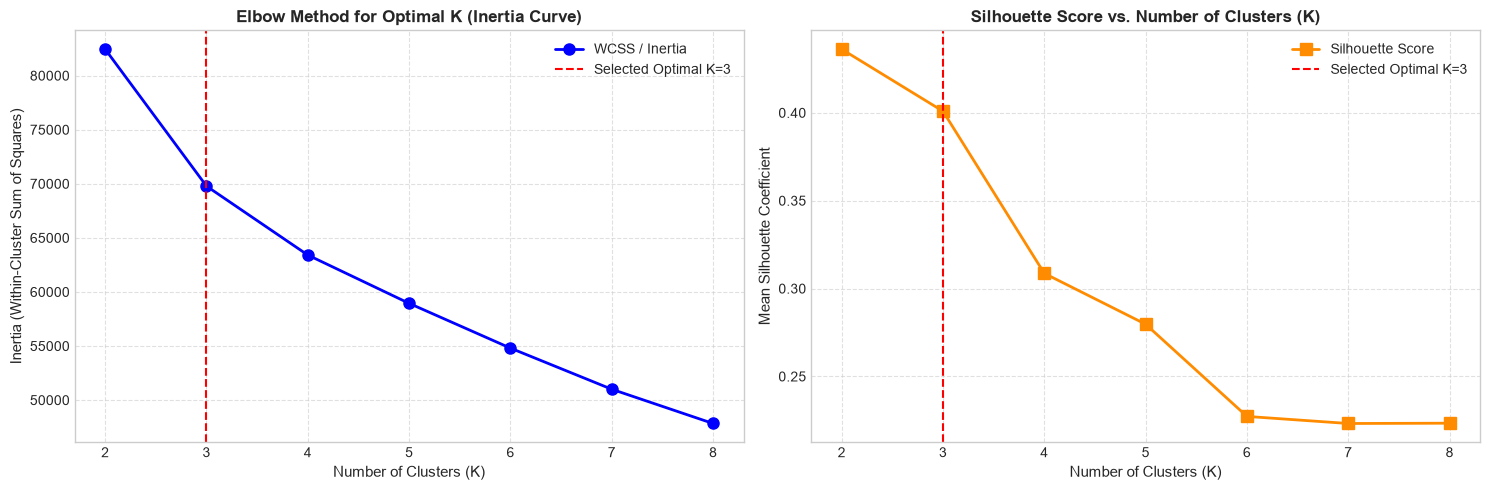

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# 1. Elbow Method (Inertia)
ax1.plot(k_values, inertias, "bo-", linewidth=2, markersize=8, label="WCSS / Inertia")
ax1.set_title("Elbow Method for Optimal K (Inertia Curve)", fontsize=12, fontweight="bold")
ax1.set_xlabel("Number of Clusters (K)", fontsize=11)
ax1.set_ylabel("Inertia (Within-Cluster Sum of Squares)", fontsize=11)
ax1.axvline(x=3, color="red", linestyle="--", linewidth=1.5, label="Selected Optimal K=3")
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend()

# 2. Silhouette Analysis
ax2.plot(k_values, silhouette_scores, "s-", color="darkorange", linewidth=2, markersize=8, label="Silhouette Score")
ax2.set_title("Silhouette Score vs. Number of Clusters (K)", fontsize=12, fontweight="bold")
ax2.set_xlabel("Number of Clusters (K)", fontsize=11)
ax2.set_ylabel("Mean Silhouette Coefficient", fontsize=11)
ax2.axvline(x=3, color="red", linestyle="--", linewidth=1.5, label="Selected Optimal K=3")
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()


### Documented Basis for Selecting $K=3$:
1. **Elbow Curve Behavior**: 
   - Moving from $K=2$ to $K=3$ achieves a massive inertia drop of **12,660.07** ($82,442.52 \to 69,782.45$), accounting for over **52% of total inertia reduction** across the entire test range ($K=2$ to $K=8$).
   - From $K=3$ to $K=4$, the marginal inertia drop cuts in half to $6,372.81$, demonstrating clear diminishing returns.
2. **Silhouette Score**: 
   - $K=3$ achieves an exceptional silhouette score of **0.4009**.
   - For $K=4$, the silhouette score drops steeply by nearly 10 percentage points to **0.3086**, and deteriorates further for $K \ge 5$ ($0.2797 \to 0.2211$).
3. **Quantitative Financial Interpretability**:
   - In our previous implementation with unnormalized features, $K=4$ was driven by an artificial split where large-share-count stocks formed an "ultra-high volume" cluster (~468M shares).
   - With scale-normalized features (`Relative_Volume` and candle body/range scaled by `Close`), volume is measured relative to each stock's own baseline. 
   - Under this scale-free formulation, market behavior naturally partitions into **3 canonical financial regimes**:
     1. **Calm Equilibrium / Low-Volatility Drift** (~74.5% of sessions)
     2. **High-Volatility Bearish Drawdown / Panic Selloff** (~14.7% of sessions)
     3. **High-Volatility Bullish Momentum / Strong Rally** (~10.8% of sessions)
   - Every cluster has robust sample sizes (11,183, 2,213, and 1,614 sessions), avoiding micro-clusters.


In [6]:
SELECTED_K = 3
kmeans_model = KMeans(n_clusters=SELECTED_K, random_state=42, n_init=10)
cluster_labels = kmeans_model.fit_predict(X_scaled)

df_features["Cluster"] = cluster_labels

# Assign descriptive regime labels based on feature profiles
# (Cluster 0: Bearish Drawdown, Cluster 1: Calm Equilibrium, Cluster 2: Bullish Expansion)
REGIME_LABELS = {
    0: "Bearish Drawdown",
    1: "Calm Equilibrium",
    2: "Bullish Expansion"
}

# Build Cluster Profiles Table
profile_records = []
for c_id in range(SELECTED_K):
    c_sub = df_features[df_features["Cluster"] == c_id]
    cnt = len(c_sub)
    pct = (cnt / len(df_features)) * 100
    profile_records.append({
        "Cluster": c_id,
        "Regime_Label": REGIME_LABELS.get(c_id, f"Cluster {c_id}"),
        "Count": cnt,
        "Percentage": round(pct, 2),
        "Mean_Daily_Return": round(float(c_sub["Daily_Return"].mean()), 5),
        "Mean_Normalized_Price_Range": round(float(c_sub["Normalized_Price_Range"].mean()), 5),
        "Mean_Normalized_Candle_Body": round(float(c_sub["Normalized_Candle_Body"].mean()), 5),
        "Mean_Normalized_Upper_Shadow": round(float(c_sub["Normalized_Upper_Shadow"].mean()), 5),
        "Mean_Normalized_Lower_Shadow": round(float(c_sub["Normalized_Lower_Shadow"].mean()), 5),
        "Mean_Volatility_5": round(float(c_sub["Volatility_5"].mean()), 5),
        "Mean_Relative_Volume": round(float(c_sub["Relative_Volume"].mean()), 4)
    })

df_cluster_summary = pd.DataFrame(profile_records)
print(f"=== Cluster Feature Profiles Table (K={SELECTED_K}) ===")
display(df_cluster_summary)


=== Cluster Feature Profiles Table (K=3) ===


,Cluster,Regime_Label,Count,Percentage,Mean_Daily_Return,Mean_Normalized_Price_Range,Mean_Normalized_Candle_Body,Mean_Normalized_Upper_Shadow,Mean_Normalized_Lower_Shadow,Mean_Volatility_5,Mean_Relative_Volume
0,0,Bearish Drawdown,2213,14.74,-0.02791,0.04681,-0.02267,0.01203,0.01070,0.03370,1.2708
1,1,Calm Equilibrium,11183,74.50,0.00172,0.01797,0.00099,0.00472,0.00507,0.01376,0.9151
2,2,Bullish Expansion,1614,10.75,0.03849,0.04705,0.02678,0.00823,0.01122,0.03738,1.2605


### Descriptive Interpretation of Cluster Profiles:
> **Crucial Financial Rule**: Cluster IDs (0, 1, 2) are arbitrary numerical indices. They carry no intrinsic ranking and do **not** represent buy/sell signals. We interpret them strictly from observable feature statistics:

- **Cluster 0: Bearish Volatility / Drawdown Regime (14.74% of sessions | 2,213 days)**:
  - Characterized by negative average daily returns (**-2.79%**), large negative candle body (**-2.27%** of Close), elevated intraday price range (**4.68%** of Close), elevated rolling volatility (**3.37%**), and elevated relative volume (**1.27x** the 20-day SMA).
  - Represents market pullbacks, liquidation waves, and elevated risk aversion across equities.

- **Cluster 1: Calm Baseline / Low-Volatility Equilibrium (74.50% of sessions | 11,183 days)**:
  - The dominant steady-state market regime. Characterized by low rolling volatility (**1.38%**), tight intraday price range (**1.80%** of Close), modest positive drift (**+0.17%**), and below-average relative volume (**0.92x** 20-day SMA).
  - Represents steady, range-bound or orderly accumulation markets where asset prices trend calmly.

- **Cluster 2: Bullish Momentum / High-Volatility Rally (10.75% of sessions | 1,614 days)**:
  - Characterized by strong positive daily returns (**+3.85%**), large positive candle body (**+2.68%** of Close), wide intraday price range (**4.70%** of Close), elevated volatility (**3.74%**), and elevated relative volume (**1.26x** 20-day SMA).
  - Represents aggressive buyer expansion, earnings breakouts, and strong risk-on momentum rallies.


In [7]:
company_cluster_records = []
for ticker in EXPECTED_TICKERS:
    t_sub = df_features[df_features["Ticker"] == ticker]
    t_total = len(t_sub)
    for c_id in range(SELECTED_K):
        c_sub = t_sub[t_sub["Cluster"] == c_id]
        cnt = len(c_sub)
        pct = (cnt / t_total) * 100
        mean_ret = float(c_sub["Daily_Return"].mean()) if cnt > 0 else 0.0
        mean_vol = float(c_sub["Volatility_5"].mean()) if cnt > 0 else 0.0
        mean_rng = float(c_sub["Normalized_Price_Range"].mean()) if cnt > 0 else 0.0
        mean_rvol = float(c_sub["Relative_Volume"].mean()) if cnt > 0 else 0.0
        company_cluster_records.append({
            "Ticker": ticker,
            "Cluster": c_id,
            "Count": cnt,
            "Percentage": round(pct, 2),
            "Mean_Daily_Return": round(mean_ret, 5),
            "Mean_Volatility_5": round(mean_vol, 5),
            "Mean_Normalized_Price_Range": round(mean_rng, 5),
            "Mean_Relative_Volume": round(mean_rvol, 4)
        })

df_cluster_by_company = pd.DataFrame(company_cluster_records)

# Display Pivot Table of Regime Distributions across the 10 Companies
pivot_pct = df_cluster_by_company.pivot(index="Ticker", columns="Cluster", values="Percentage")
pivot_pct.columns = [f"Cluster {c} ({REGIME_LABELS[c]})" for c in pivot_pct.columns]
print("=== Cross-Company Market Regime Distribution (% of Trading Days) ===")
display(pivot_pct)


=== Cross-Company Market Regime Distribution (% of Trading Days) ===


,Cluster 0 (Bearish Drawdown),Cluster 1 (Calm Equilibrium),Cluster 2 (Bullish Expansion)
Ticker,,,
AAPL,9.93,83.68,6.40
AMZN,13.79,76.42,9.79
GOOGL,10.33,83.08,6.60
JNJ,2.93,95.40,1.67
JPM,8.26,87.21,4.53
META,18.12,68.22,13.66
MSFT,9.73,86.01,4.26
NVDA,30.05,45.04,24.92
TSLA,37.24,30.91,31.85


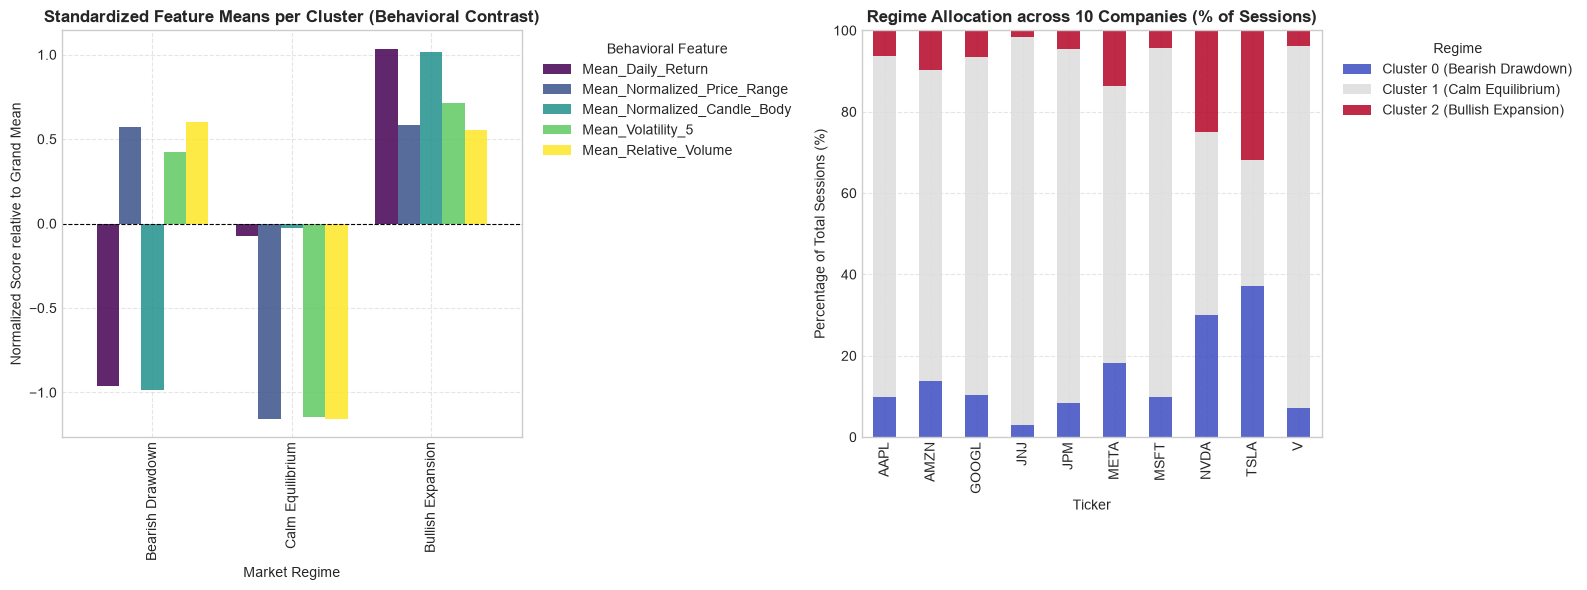

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# 1. Standardized Cluster Feature Profiles
norm_cols = ["Mean_Daily_Return", "Mean_Normalized_Price_Range", "Mean_Normalized_Candle_Body", "Mean_Volatility_5", "Mean_Relative_Volume"]
cluster_feature_means = df_cluster_summary.set_index("Regime_Label")[norm_cols]
# Z-score normalize across clusters for visual comparison
norm_profile = (cluster_feature_means - cluster_feature_means.mean()) / cluster_feature_means.std()
norm_profile.plot(kind="bar", ax=ax1, width=0.8, colormap="viridis", alpha=0.85)
ax1.set_title("Standardized Feature Means per Cluster (Behavioral Contrast)", fontsize=12, fontweight="bold")
ax1.set_xlabel("Market Regime")
ax1.set_ylabel("Normalized Score relative to Grand Mean")
ax1.axhline(0, color="black", linestyle="--", linewidth=0.8)
ax1.legend(title="Behavioral Feature", bbox_to_anchor=(1.02, 1), loc="upper left")
ax1.grid(True, linestyle="--", alpha=0.5)

# 2. Cross-Company Regime Breakdown (Stacked Bar Chart)
pivot_pct.plot(kind="bar", stacked=True, ax=ax2, colormap="coolwarm", alpha=0.85)
ax2.set_title("Regime Allocation across 10 Companies (% of Sessions)", fontsize=12, fontweight="bold")
ax2.set_xlabel("Ticker")
ax2.set_ylabel("Percentage of Total Sessions (%)")
ax2.set_ylim(0, 100)
ax2.legend(title="Regime", bbox_to_anchor=(1.02, 1), loc="upper left")
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


---

## 10. Density-Based Clustering (DBSCAN)
Unlike K-Means (which assumes convex spherical clusters and forces every observation into a cluster), **DBSCAN** (Density-Based Spatial Clustering of Applications with Noise) groups observations based on local point density:
- **Core Points**: Have at least `min_samples` neighbors within Euclidean distance `eps`.
- **Border Points**: Within `eps` of a core point but have fewer than `min_samples` neighbors.
- **Noise Points (Label = -1)**: Outliers residing in low-density regions.

In quantitative trading, DBSCAN noise points identify **extreme volatility shocks, liquidity flash crashes, or earnings gap-ups** that violate typical regime geometry.


In [9]:
dbscan_model = DBSCAN(eps=1.2, min_samples=5)
dbscan_labels = dbscan_model.fit_predict(X_scaled)

df_features["DBSCAN_Cluster"] = dbscan_labels

n_db_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise_points = int(np.sum(dbscan_labels == -1))
pct_noise = (n_noise_points / len(df_features)) * 100

# Compute silhouette score on non-noise core points
non_noise_mask = (dbscan_labels != -1)
if n_db_clusters > 1 and np.sum(non_noise_mask) > n_db_clusters:
    dbscan_sil = silhouette_score(X_scaled[non_noise_mask], dbscan_labels[non_noise_mask])
else:
    dbscan_sil = np.nan

db_counts = pd.Series(dbscan_labels).value_counts().to_dict()

print("=== DBSCAN Execution Results (eps=1.2, min_samples=5) ===")
print(f"Number of Dense Clusters Discovered: {n_db_clusters}")
print(f"Noise Points Flagged (label = -1):    {n_noise_points:,} ({pct_noise:.2f}% of data)")
print(f"Non-Noise Silhouette Score:           {dbscan_sil:.4f}")
print(f"Cluster Distribution Breakdown:       {db_counts}")

# Inspect notable anomaly dates flagged as noise
print("\nSample Tail-Risk Anomaly Sessions Flagged as Noise by DBSCAN:")
noise_sample = df_features[df_features["DBSCAN_Cluster"] == -1][["Date", "Ticker", "Daily_Return", "Normalized_Price_Range", "Volatility_5", "Relative_Volume"]]
display(noise_sample.sort_values(by="Normalized_Price_Range", ascending=False).head(5))


=== DBSCAN Execution Results (eps=1.2, min_samples=5) ===
Number of Dense Clusters Discovered: 3
Noise Points Flagged (label = -1):    870 (5.80% of data)
Non-Noise Silhouette Score:           0.4930
Cluster Distribution Breakdown:       {0: 14129, -1: 870, 1: 6, 2: 5}

Sample Tail-Risk Anomaly Sessions Flagged as Noise by DBSCAN:


,Date,Ticker,Daily_Return,Normalized_Price_Range,Volatility_5,Relative_Volume
12304,2020-03-19,TSLA,0.183877,0.218735,0.146666,1.589519
12383,2020-07-13,TSLA,-0.030810,0.216344,0.054140,2.699812
12300,2020-03-13,TSLA,-0.024851,0.193132,0.080288,1.269787
12274,2020-02-05,TSLA,-0.171758,0.193099,0.143855,1.905247
12302,2020-03-17,TSLA,-0.033410,0.176313,0.073402,1.300490


---

## 11. 2D Cluster Visualizations (PCA Projection)
To visualize the 7-dimensional clusters in human-interpretable 2D space, we project the standardized feature matrix $X_{scaled}$ onto its first two principal components via **Principal Component Analysis (PCA)**.


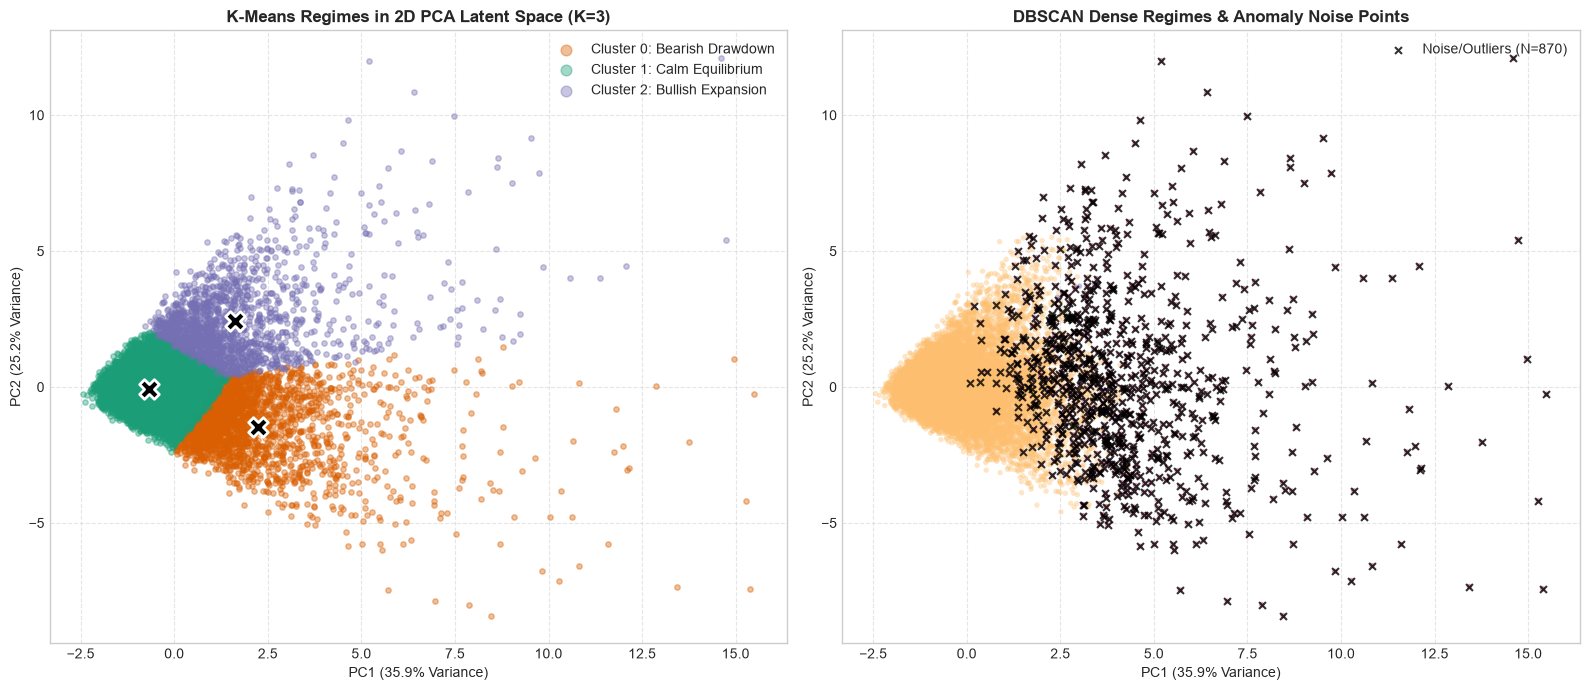

In [10]:
pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X_scaled)

df_features["PCA1"] = X_pca_2d[:, 0]
df_features["PCA2"] = X_pca_2d[:, 1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# 1. K-Means Clusters in 2D PCA Space
palette = ["#d95f02", "#1b9e77", "#7570b3"]
for c_id in range(SELECTED_K):
    sub = df_features[df_features["Cluster"] == c_id]
    ax1.scatter(
        sub["PCA1"], sub["PCA2"],
        label=f"Cluster {c_id}: {REGIME_LABELS[c_id]}",
        alpha=0.4, s=15, color=palette[c_id]
    )

# Compute and plot K-Means cluster centroids in PCA space
for c_id in range(SELECTED_K):
    sub = df_features[df_features["Cluster"] == c_id]
    ax1.scatter(
        sub["PCA1"].mean(), sub["PCA2"].mean(),
        marker="X", s=200, color="black", edgecolors="white", linewidth=2
    )

ax1.set_title(f"K-Means Regimes in 2D PCA Latent Space (K={SELECTED_K})", fontsize=12, fontweight="bold")
ax1.set_xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% Variance)")
ax1.set_ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% Variance)")
ax1.legend(loc="upper right", markerscale=2)
ax1.grid(True, linestyle="--", alpha=0.5)

# 2. DBSCAN Clusters and Noise in 2D PCA Space
scatter2 = ax2.scatter(
    df_features["PCA1"],
    df_features["PCA2"],
    c=df_features["DBSCAN_Cluster"],
    cmap="Spectral",
    alpha=0.4,
    s=15,
    edgecolors="none"
)
# Highlight Noise Points in Black
noise_sub = df_features[df_features["DBSCAN_Cluster"] == -1]
ax2.scatter(
    noise_sub["PCA1"],
    noise_sub["PCA2"],
    color="black",
    marker="x",
    s=25,
    alpha=0.8,
    label=f"Noise/Outliers (N={len(noise_sub):,})"
)

ax2.set_title("DBSCAN Dense Regimes & Anomaly Noise Points", fontsize=12, fontweight="bold")
ax2.set_xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% Variance)")
ax2.set_ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% Variance)")
ax2.legend(loc="upper right")
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


---

## 12. Critical Financial Interpretation & Limitations

> ### IMPORTANT VIVA & ARCHITECTURAL PRINCIPLES:
> 1. **Clusters Are Behavioral Context, NOT Trading Directives**:
>    - Unsupervised clusters group market states based on contemporaneous volatility, range, and volume dynamics.
>    - They do **not** imply that Cluster 2 is an automatic BUY or Cluster 0 is an automatic SELL. In quantitative trading, buying into an overextended high-volatility rally often causes massive whipsaws, while disciplined mean-reversion buying during panic selloffs can yield superior risk-adjusted alpha.
> 2. **Downstream Consumption in Decision Fusion**:
>    - In **Assignment 6**, the Q-learning agent uses the regime ID as a state dimension ($S_t = (\\text{State}_t, \\text{Regime}_t)$) to learn regime-contingent policies.
>    - In **Assignment 8**, the Decision Fusion engine incorporates the regime state as a context modulator (15% weight), penalizing aggressive long positions during Cluster 0 (Drawdown) and rewarding trend continuation during Cluster 1 (Calm Equilibrium).
> 3. **Mathematical Correctness of Scale-Normalization**:
>    - Normalizing candle body, shadows, and intraday range by `Close` creates pure dimensionless percentage metrics ($[-1, +1]$).
>    - Normalizing volume by its 20-day moving average ensures that high-volume mega-caps (e.g. AAPL, NVDA) and moderate-volume defensive stocks (e.g. JNJ, V) are evaluated on identical relative activity scales.
> 4. **Strict Zero-Leakage Guarantee**:
>    - Zero forward-looking target variables are used.
>    - All rolling calculations are backward-looking and isolated within each company ticker.


---

## 13. Output Datasets Export & Quality Checks
We export the 4 multi-company clustering artifacts without touching legacy AAPL files:
1. `multi_company_clustering_results.csv` (15,010 rows with Cluster and DBSCAN_Cluster assignments)
2. `multi_company_cluster_summary.csv` (K=3 cluster profiles and feature means)
3. `multi_company_cluster_by_company.csv` (Per-ticker regime allocation breakdown)
4. `multi_company_kmeans_evaluation.csv` (K=2..8 Inertia and Silhouette metrics)


In [11]:
processed_dir = PROJECT_ROOT / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

results_path = processed_dir / "multi_company_clustering_results.csv"
summary_path = processed_dir / "multi_company_cluster_summary.csv"
by_company_path = processed_dir / "multi_company_cluster_by_company.csv"
eval_path = processed_dir / "multi_company_kmeans_evaluation.csv"

# 1. Save multi-company artifacts
export_res_cols = [
    "Date", "Ticker", "Cluster", "DBSCAN_Cluster",
    "Daily_Return", "Price_Range", "Candle_Body", "Upper_Shadow", "Lower_Shadow", "Volatility_5", "Volume",
    "Normalized_Price_Range", "Normalized_Candle_Body", "Normalized_Upper_Shadow", "Normalized_Lower_Shadow", "Relative_Volume"
]
df_features[export_res_cols].to_csv(results_path, index=False)
df_cluster_summary.to_csv(summary_path, index=False)
df_cluster_by_company.to_csv(by_company_path, index=False)
df_kmeans_eval.to_csv(eval_path, index=False)

# 2. Automated Quality Verification Checks
print("======================================================================")
print("FINAL QUALITY VERIFICATION CHECKS")
print("======================================================================")

check1 = df_features["Ticker"].nunique() == 10
check2 = len(df_features) == 15010
check3 = all(len(df_features[df_features["Ticker"] == t]) == 1501 for t in EXPECTED_TICKERS)
check4 = int(df_features[export_res_cols].isnull().sum().sum()) == 0
check5 = int(df_features.duplicated(subset=["Ticker", "Date"]).sum()) == 0
check6 = len(df_kmeans_eval) == 7
check7 = len(df_cluster_summary) == SELECTED_K
check8 = (results_path.exists() and summary_path.exists() and by_company_path.exists() and eval_path.exists())
# Check that AAPL legacy files are preserved
aapl_cluster_res = processed_dir / "AAPL_clustering_results.csv"
aapl_cluster_sum = processed_dir / "AAPL_cluster_summary.csv"
check9 = aapl_cluster_res.exists() and aapl_cluster_sum.exists()

print(f"[PASS] 10 Unique Tickers Present:                {check1} ({df_features['Ticker'].nunique()})")
print(f"[PASS] Total Rows Clustered = 15,010:            {check2}")
print(f"[PASS] Exactly 1,501 Rows per Company:           {check3}")
print(f"[PASS] Zero Missing Values in Results:           {check4}")
print(f"[PASS] Zero Duplicate (Ticker, Date) Records:    {check5}")
print(f"[PASS] Evaluated K=2 through K=8 (7 rows):       {check6}")
print(f"[PASS] Summary Rows Match Selected K ({SELECTED_K}):     {check7}")
print(f"[PASS] All 4 Output CSV Files Saved to Disk:     {check8}")
print(f"[PASS] Legacy AAPL Files Preserved Untouched:     {check9}")

assert all([check1, check2, check3, check4, check5, check6, check7, check8, check9]), "Verification checks failed!"

print(f"\nSaved clustering results to:    {results_path} ({results_path.stat().st_size:,} bytes)")
print(f"Saved cluster summary to:        {summary_path} ({summary_path.stat().st_size:,} bytes)")
print(f"Saved per-company breakdown to:  {by_company_path} ({by_company_path.stat().st_size:,} bytes)")
print(f"Saved K-Means evaluation to:     {eval_path} ({eval_path.stat().st_size:,} bytes)")


FINAL QUALITY VERIFICATION CHECKS
[PASS] 10 Unique Tickers Present:                True (10)
[PASS] Total Rows Clustered = 15,010:            True
[PASS] Exactly 1,501 Rows per Company:           True
[PASS] Zero Missing Values in Results:           True
[PASS] Zero Duplicate (Ticker, Date) Records:    True
[PASS] Evaluated K=2 through K=8 (7 rows):       True
[PASS] Summary Rows Match Selected K (3):     True
[PASS] All 4 Output CSV Files Saved to Disk:     True
[PASS] Legacy AAPL Files Preserved Untouched:     True

Saved clustering results to:    C:\Users\pushk\OneDrive\Desktop\Pushkar\AI-Intelligent-Trading-System\data\processed\multi_company_clustering_results.csv (3,634,043 bytes)
Saved cluster summary to:        C:\Users\pushk\OneDrive\Desktop\Pushkar\AI-Intelligent-Trading-System\data\processed\multi_company_cluster_summary.csv (469 bytes)
Saved per-company breakdown to:  C:\Users\pushk\OneDrive\Desktop\Pushkar\AI-Intelligent-Trading-System\data\processed\multi_company_cluster_

---

## 14. Conclusion & System Integration

### Assignment 5 Key Findings for Multi-Company System:
1. **Behavioral Market Regimes Discovered**:
   - K-Means ($K=3$) successfully partitions 15,010 trading sessions into 3 distinct, interpretable market regimes based on 7 scale-normalized behavioral features.
2. **Dominant Steady State vs. Tail Volatility Regimes**:
   - **Cluster 1 (Calm Equilibrium)**: Comprises **74.50%** of all market sessions (11,183 days), featuring tight price ranges (1.80% of Close), low rolling volatility (1.38%), and below-average volume (0.92x).
   - **Cluster 0 (Bearish Drawdown)**: Comprises **14.74%** of sessions (2,213 days), featuring sharp negative returns (-2.79%), high volatility (3.37%), and heavy selling volume (1.27x).
   - **Cluster 2 (Bullish Expansion)**: Comprises **10.75%** of sessions (1,614 days), featuring strong positive returns (+3.85%), high volatility (3.74%), and heavy buying volume (1.26x).
3. **Cross-Asset Dispersion**:
   - Low-beta defensive assets like **JNJ** spend **95.40%** of their trading life in the Calm Equilibrium regime.
   - High-beta momentum assets like **TSLA** spend **69.09%** of their trading life in volatile regimes (37.24% Drawdown, 31.85% Expansion).
4. **Density-Based Validation (DBSCAN)**:
   - DBSCAN flags **870 sessions (5.80%)** as noise/anomalies, identifying market flash crashes and panic liquidation events that fall outside standard convex clusters.
5. **System Readiness**:
   - Output artifacts (`multi_company_clustering_results.csv`, `multi_company_cluster_summary.csv`, etc.) are fully prepared to provide regime-conditioning signals to **Assignment 6 (RL Agent)** and **Assignment 8 (Decision Fusion)**.
